# Yellow Sigatoka EDA and Dataset Validation

This notebook explores the training and validation scenarios and compares their environmental conditions with the historical NASA reference. The reserved test dataset is not loaded or inspected.

## 1. Import Libraries

Use pandas for tables, NumPy for validity checks, and Matplotlib/Seaborn for the requested plots.

In [1]:
# Import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load Data

Load only the training, validation, and historical reference CSVs. The held-out test file remains untouched.

In [2]:
# Load the training, validation, and historical reference data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "datasets" / "yellow_sigatoka"

train_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_train.csv")
validation_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_validation.csv")
historical_df = pd.read_csv(DATA_DIR / "YS_NASA_HISTORICAL_2022_2024.csv")

features = [
    "mean_temp_previous_14d_c",
    "wet_hours_previous_14d",
    "consecutive_wetness_hours",
]
target = "risk_score"

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Historical reference shape:", historical_df.shape)


Training shape: (4200, 32)
Validation shape: (900, 32)
Historical reference shape: (25969, 32)


## 3. Dataset Overview

Review the training rows, schema, and risk-level counts. Historical records remain a separate reference dataset.

In [3]:
# Inspect the training data structure
train_df.head()


,record_id,scenario_id,data_origin,timestamp_utc,air_temp_c,relative_humidity_pct,rainfall_mm_hr,dew_point_c,dew_point_depression_c,wind_speed_m_s,solar_radiation_original_nasa_units,estimated_leaf_wet,consecutive_wetness_hours,wet_hours_previous_24h,wet_hours_previous_72h,wet_hours_previous_14d,rainfall_previous_24h_mm,rainfall_previous_72h_mm,rainfall_previous_14d_mm,mean_temp_previous_24h_c,mean_temp_previous_14d_c,mean_rh_previous_24h_pct,mean_rh_previous_14d_pct,temperature_suitability,wetness_suitability,bonfim_favourable_flag,risk_score,risk_level,risk_score_type,wetness_estimation_method,label_method,split
0,YS_SIM_002503,YS_SIM_002503,SIMULATED_NASA_ANALOGUE,NaN,30.982,77.026,0.000,26.482,4.501,6.779,2.070,0,0,11,26,95,8.363,14.835,41.177,30.264,31.675,85.093,81.324,0.4660,0.3714,0,15.230,Low,RELATIVE_ENVIRONMENTAL_SUITABILITY_NOT_PROBABI...,RH>=95 OR (T-DEW<=1.5 AND SOLAR<0.15) OR RAIN>...,PROJECT_HEURISTIC_ANCHORED_TO_BONFIM2024_AND_P...,train
1,YS_SIM_002461,YS_SIM_002461,SIMULATED_NASA_ANALOGUE,NaN,20.346,96.977,0.000,19.850,0.496,0.676,0.000,1,11,23,69,280,5.898,19.591,79.260,21.276,20.475,96.762,94.095,0.7338,1.0000,1,69.958,High,RELATIVE_ENVIRONMENTAL_SUITABILITY_NOT_PROBABI...,RH>=95 OR (T-DEW<=1.5 AND SOLAR<0.15) OR RAIN>...,PROJECT_HEURISTIC_ANCHORED_TO_BONFIM2024_AND_P...,train
2,YS_SIM_002240,YS_SIM_002240,SIMULATED_NASA_ANALOGUE,NaN,28.290,76.573,0.000,23.779,4.511,3.383,0.000,0,0,6,46,199,3.689,18.632,96.474,28.744,27.928,81.665,88.502,0.7658,0.9657,0,65.076,High,RELATIVE_ENVIRONMENTAL_SUITABILITY_NOT_PROBABI...,RH>=95 OR (T-DEW<=1.5 AND SOLAR<0.15) OR RAIN>...,PROJECT_HEURISTIC_ANCHORED_TO_BONFIM2024_AND_P...,train
3,YS_SIM_010173,YS_SIM_010173,SIMULATED_NASA_ANALOGUE,NaN,39.237,90.139,0.000,37.319,1.918,6.094,1.610,0,0,2,4,43,0.000,0.000,16.954,37.291,37.280,79.406,78.027,0.0176,0.0743,0,0.115,No Risk,RELATIVE_ENVIRONMENTAL_SUITABILITY_NOT_PROBABI...,RH>=95 OR (T-DEW<=1.5 AND SOLAR<0.15) OR RAIN>...,PROJECT_HEURISTIC_ANCHORED_TO_BONFIM2024_AND_P...,train
4,YS_SIM_002334,YS_SIM_002334,SIMULATED_NASA_ANALOGUE,NaN,24.085,97.024,0.521,23.583,0.502,5.807,0.792,1,1,13,34,97,3.648,11.792,37.363,22.685,22.601,89.351,82.388,0.8589,0.4621,0,35.497,Moderate,RELATIVE_ENVIRONMENTAL_SUITABILITY_NOT_PROBABI...,RH>=95 OR (T-DEW<=1.5 AND SOLAR<0.15) OR RAIN>...,PROJECT_HEURISTIC_ANCHORED_TO_BONFIM2024_AND_P...,train


In [4]:
# Show column types and non-missing counts
train_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 32 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   record_id                            4200 non-null   str    
 1   scenario_id                          4200 non-null   str    
 2   data_origin                          4200 non-null   str    
 3   timestamp_utc                        0 non-null      float64
 4   air_temp_c                           4200 non-null   float64
 5   relative_humidity_pct                4200 non-null   float64
 6   rainfall_mm_hr                       4200 non-null   float64
 7   dew_point_c                          4200 non-null   float64
 8   dew_point_depression_c               4200 non-null   float64
 9   wind_speed_m_s                       4200 non-null   float64
 10  solar_radiation_original_nasa_units  4200 non-null   float64
 11  estimated_leaf_wet                   4200

In [5]:
# Count records and scenario IDs
overview = pd.DataFrame({
    "dataset": ["Training", "Validation", "Historical reference"],
    "rows": [len(train_df), len(validation_df), len(historical_df)],
    "columns": [train_df.shape[1], validation_df.shape[1], historical_df.shape[1]],
    "unique scenario IDs": [train_df["scenario_id"].nunique(), validation_df["scenario_id"].nunique(), historical_df["scenario_id"].nunique()],
})
display(overview)
print("Duplicate training scenario IDs:", train_df["scenario_id"].duplicated().sum())
print("Duplicate validation scenario IDs:", validation_df["scenario_id"].duplicated().sum())
print("Shared train/validation scenario IDs:", len(set(train_df["scenario_id"].dropna()) & set(validation_df["scenario_id"].dropna())))


,dataset,rows,columns,unique scenario IDs
0,Training,4200,32,4200
1,Validation,900,32,900
2,Historical reference,25969,32,0


Duplicate training scenario IDs: 0
Duplicate validation scenario IDs: 0
Shared train/validation scenario IDs: 0


## 4. Missing Values

Missing values are counted in all three loaded datasets. Some metadata fields may intentionally be empty, such as synthetic timestamps and historical scenario IDs.

In [6]:
# Check missing values
missing_values = pd.DataFrame({
    "training": train_df.isna().sum(),
    "validation": validation_df.isna().sum(),
    "historical_reference": historical_df.isna().sum(),
}).fillna(0).astype(int)
display(missing_values.loc[missing_values.sum(axis=1) > 0])
print("Total missing values ? training:", int(train_df.isna().sum().sum()))
print("Total missing values ? validation:", int(validation_df.isna().sum().sum()))
print("Total missing values ? historical reference:", int(historical_df.isna().sum().sum()))


,training,validation,historical_reference
scenario_id,0,0,25969
timestamp_utc,4200,900,0


Total missing values ? training: 4200
Total missing values ? validation: 900


Total missing values ? historical reference: 25969


## 5. Risk Score Distribution

Risk scores are a project-defined environmental suitability index from 0 to 100. They are not measured disease probabilities.

,Training,Validation
count,4200.000,900.000
mean,36.687,36.754
std,30.931,30.796
min,0.000,0.000
25%,5.038,5.068
50%,29.984,29.993
75%,64.987,64.929
max,99.760,99.751


Training scores within 0 to 100:

 True
Validation scores within 0 to 100: True


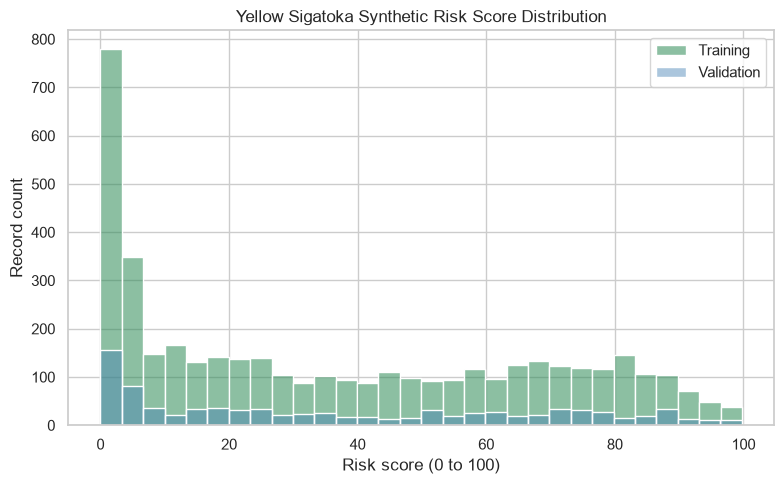

In [7]:
# Check the score range and summary
score_summary = pd.DataFrame({
    "Training": train_df[target].describe(),
    "Validation": validation_df[target].describe(),
}).round(3)
display(score_summary)
print("Training scores within 0 to 100:", bool(train_df[target].between(0, 100).all()))
print("Validation scores within 0 to 100:", bool(validation_df[target].between(0, 100).all()))

# Plot the risk score distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=train_df, x=target, bins=30, color="seagreen", label="Training", alpha=0.55)
sns.histplot(data=validation_df, x=target, bins=30, color="steelblue", label="Validation", alpha=0.45)
plt.title("Yellow Sigatoka Synthetic Risk Score Distribution")
plt.xlabel("Risk score (0 to 100)")
plt.ylabel("Record count")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Risk Level Distribution

The Yellow Sigatoka thresholds are No Risk < 5, Low 5 to <30, Moderate 30 to <65, and High >=65.

,Training,Validation
risk_level,,
No Risk,1050,225
Low,1050,225
Moderate,1050,225
High,1050,225


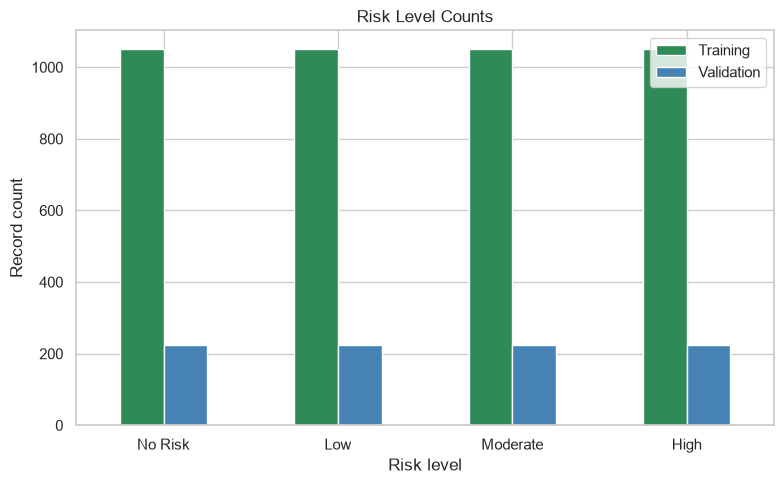

In [8]:
# Count the risk levels
risk_levels = ["No Risk", "Low", "Moderate", "High"]
risk_counts = pd.DataFrame({
    "Training": train_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0),
    "Validation": validation_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0),
})
display(risk_counts)

# Plot records per risk level
risk_counts.plot(kind="bar", figsize=(8, 5), color=["seagreen", "steelblue"])
plt.title("Risk Level Counts")
plt.xlabel("Risk level")
plt.ylabel("Record count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Environmental Features

Review the three proposed score inputs and related weather fields without treating every available column as an approved model input.

Training                         \
     mean_temp_previous_14d_c wet_hours_previous_14d   
min                    13.710                  8.000   
mean                   27.933                164.876   
max                    39.457                331.000   

                                             Validation  \
     consecutive_wetness_hours mean_temp_previous_14d_c   
min                      0.000                   15.772   
mean                     6.698                   27.914   
max                    111.000                   39.249   

                                                       
     wet_hours_previous_14d consecutive_wetness_hours  
min                    8.00                     0.000  
mean                 163.28                     6.786  
max                  324.00                   100.000

,air_temp_c,relative_humidity_pct,rainfall_mm_hr,estimated_leaf_wet,consecutive_wetness_hours,wet_hours_previous_14d
count,4200.000,4200.000,4200.000,4200.000,4200.000,4200.000
mean,27.913,86.642,0.202,0.496,6.698,164.876
std,5.974,12.269,0.742,0.500,12.389,94.458
min,11.426,44.482,0.000,0.000,0.000,8.000
25%,23.360,76.308,0.000,0.000,0.000,71.000
50%,27.931,93.474,0.000,0.000,0.000,169.000
75%,32.831,97.250,0.000,1.000,8.000,252.000
max,40.000,100.000,7.908,1.000,111.000,331.000


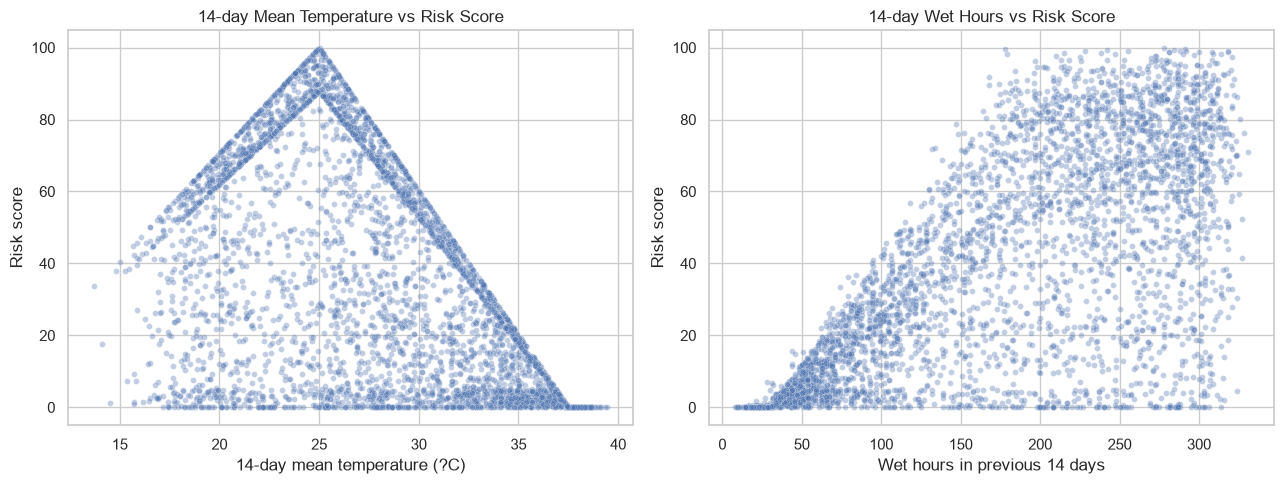

In [9]:
# Review temperature and wetness features
feature_summary = pd.concat({
    "Training": train_df[features].describe().loc[["min", "mean", "max"]],
    "Validation": validation_df[features].describe().loc[["min", "mean", "max"]],
}, axis=1).round(3)
display(feature_summary)

weather_columns = ["air_temp_c", "relative_humidity_pct", "rainfall_mm_hr", "estimated_leaf_wet", "consecutive_wetness_hours", "wet_hours_previous_14d"]
display(train_df[weather_columns].describe().round(3))

# Plot the main environmental features against risk score
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=train_df, x="mean_temp_previous_14d_c", y=target, alpha=0.35, s=18, ax=axes[0])
axes[0].set_title("14-day Mean Temperature vs Risk Score")
axes[0].set_xlabel("14-day mean temperature (?C)")
axes[0].set_ylabel("Risk score")
sns.scatterplot(data=train_df, x="wet_hours_previous_14d", y=target, alpha=0.35, s=18, ax=axes[1])
axes[1].set_title("14-day Wet Hours vs Risk Score")
axes[1].set_xlabel("Wet hours in previous 14 days")
axes[1].set_ylabel("Risk score")
plt.tight_layout()
plt.show()


## 8. Feature Relationships

The correlation plot is descriptive. The score is computed from these inputs, so association is expected and does not establish disease prediction.

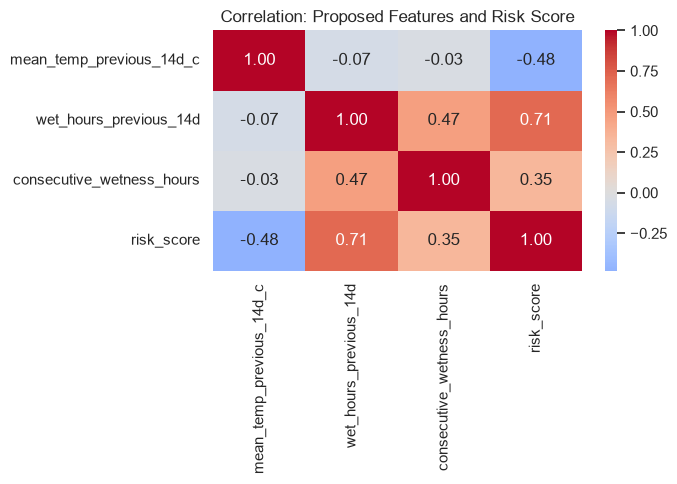

,mean_temp_previous_14d_c,wet_hours_previous_14d,consecutive_wetness_hours,risk_score
mean_temp_previous_14d_c,1.000,-0.065,-0.033,-0.481
wet_hours_previous_14d,-0.065,1.000,0.471,0.714
consecutive_wetness_hours,-0.033,0.471,1.000,0.345
risk_score,-0.481,0.714,0.345,1.000


In [10]:
# Check correlations among the three proposed inputs and target
correlation_data = train_df[features + [target]].corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(correlation_data, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation: Proposed Features and Risk Score")
plt.tight_layout()
plt.show()
display(correlation_data.round(3))


## 9. Data Quality Checks

Check expected ranges, labels, wetness indicators, scenario IDs, and the consistency between current wetness and consecutive wetness duration.

In [11]:
# Check data quality in training and validation

def expected_level(scores):
    return pd.cut(scores, bins=[-np.inf, 5, 30, 65, np.inf], right=False,
                  labels=["No Risk", "Low", "Moderate", "High"])

quality_rows = []
for split_name, frame in [("Training", train_df), ("Validation", validation_df)]:
    expected = expected_level(frame[target])
    quality_rows.extend([
        [split_name, "Rows", len(frame), "Expected 4200 train / 900 validation"],
        [split_name, "Missing values in three main features", int(frame[features].isna().sum().sum()), "Should be 0"],
        [split_name, "Non-finite values in three main features", int((~np.isfinite(frame[features].to_numpy(dtype=float))).sum()), "Should be 0"],
        [split_name, "Negative wetness durations", int((frame[["consecutive_wetness_hours", "wet_hours_previous_14d"]] < 0).sum().sum()), "Should be 0"],
        [split_name, "14-day wet hours above 336", int((frame["wet_hours_previous_14d"] > 336).sum()), "Should be 0"],
        [split_name, "Invalid wetness indicators (not 0/1)", int((~frame["estimated_leaf_wet"].isin([0, 1])).sum()), "Should be 0"],
        [split_name, "Humidity outside 0 to 100", int((~frame["relative_humidity_pct"].between(0, 100)).sum()), "Should be 0"],
        [split_name, "Risk scores outside 0 to 100", int((~frame[target].between(0, 100)).sum()), "Should be 0"],
        [split_name, "Risk-level label mismatches", int((expected.astype(str) != frame["risk_level"].astype(str)).sum()), "Should be 0"],
        [split_name, "Duplicate scenario IDs", int(frame["scenario_id"].duplicated().sum()), "Should be 0"],
        [split_name, "Current wetness / streak disagreement", int(((frame["estimated_leaf_wet"] == 1) != (frame["consecutive_wetness_hours"] > 0)).sum()), "Review if nonzero"],
    ])
quality_checks = pd.DataFrame(quality_rows, columns=["Dataset", "Check", "Count", "Interpretation"])
display(quality_checks)
shared_scenario_ids = set(train_df["scenario_id"].dropna()) & set(validation_df["scenario_id"].dropna())
print("Shared train/validation scenario IDs:", len(shared_scenario_ids))


,Dataset,Check,Count,Interpretation
0,Training,Rows,4200,Expected 4200 train / 900 validation
1,Training,Missing values in three main features,0,Should be 0
2,Training,Non-finite values in three main features,0,Should be 0
3,Training,Negative wetness durations,0,Should be 0
4,Training,14-day wet hours above 336,0,Should be 0
5,Training,Invalid wetness indicators (not 0/1),0,Should be 0
6,Training,Humidity outside 0 to 100,0,Should be 0
7,Training,Risk scores outside 0 to 100,0,Should be 0
8,Training,Risk-level label mismatches,0,Should be 0
9,Training,Duplicate scenario IDs,0,Should be 0


Shared train/validation scenario IDs: 0


## 10. EDA Summary

Compare the training distribution with the historical reference. Historical heuristic risk labels are not confirmed disease observations.

In [12]:
# Compare basic weather ranges with the historical reference
comparison_columns = {
    "Air temperature (?C)": "air_temp_c",
    "Relative humidity (%)": "relative_humidity_pct",
    "14-day mean temperature (?C)": "mean_temp_previous_14d_c",
    "14-day wet hours": "wet_hours_previous_14d",
}
comparison_rows = []
for label, column in comparison_columns.items():
    comparison_rows.append({
        "Measure": label,
        "Train min": train_df[column].min(),
        "Train median": train_df[column].median(),
        "Train max": train_df[column].max(),
        "Historical min": historical_df[column].min(),
        "Historical median": historical_df[column].median(),
        "Historical max": historical_df[column].max(),
    })
weather_comparison = pd.DataFrame(comparison_rows).set_index("Measure").round(2)
display(weather_comparison)

print("Train risk level counts:")
display(train_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0).to_frame("count"))
print("Validation risk level counts:")
display(validation_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0).to_frame("count"))


,Train min,Train median,Train max,Historical min,Historical median,Historical max
Measure,,,,,,
Air temperature (?C),11.43,27.93,40.00,19.56,26.87,36.33
Relative humidity (%),44.48,93.47,100.00,34.74,86.19,100.00
14-day mean temperature (?C),13.71,27.86,39.46,24.18,27.02,30.07
14-day wet hours,8.00,169.00,331.00,2.00,97.00,261.00


Train risk level counts:


,count
risk_level,
No Risk,1050
Low,1050
Moderate,1050
High,1050


Validation risk level counts:


,count
risk_level,
No Risk,225
Low,225
Moderate,225
High,225


### Interpretation

The proposed inputs are the exact variables used by the project score formula. Suitability components, the favorable-condition flag, risk category, and source/label metadata should not be ordinary predictors. Strong predictive results would show that a model can reproduce this synthetic formula; they would not validate real disease detection. Scenario IDs are disjoint, but the builder permits overlapping NASA source windows across scenarios, so the splits may share underlying weather information.

### Score formula

The score first calculates temperature suitability from the 14-day mean temperature, then wetness suitability from the 14-day wet hours, and continuity from the consecutive wetness hours. It combines wetness and continuity as `0.88 x wetness suitability + 0.12 x continuity`, multiplies by temperature suitability, and scales the result to 0 to 100. These are project-defined rules, not a calibrated disease model.

In [13]:
# Save the short EDA report
from IPython.display import Markdown, display

risk_distribution = pd.DataFrame({
    "Training": train_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0),
    "Validation": validation_df["risk_level"].value_counts().reindex(risk_levels, fill_value=0),
})
train_missing = int(train_df.isna().sum().sum())
validation_missing = int(validation_df.isna().sum().sum())
historical_missing = int(historical_df.isna().sum().sum())
quality_issues = quality_checks[(quality_checks["Count"] > 0) & (quality_checks["Check"] != "Rows")]

report_lines = [
    "# Yellow Sigatoka EDA Report",
    "",
    "## Dataset overview",
    f"- Training: {len(train_df):,} rows, {train_df.shape[1]} columns.",
    f"- Validation: {len(validation_df):,} rows, {validation_df.shape[1]} columns.",
    f"- NASA historical reference: {len(historical_df):,} rows, {historical_df.shape[1]} columns. It was kept separate from simulated training data.",
    "- The reserved test CSV was not loaded or inspected. The dataset builder was read but not run.",
    "",
    "## Main environmental features",
    "The proposed inputs are `mean_temp_previous_14d_c`, `wet_hours_previous_14d`, and `consecutive_wetness_hours`. They are within the expected finite ranges observed in the scenarios; see the quality table in the notebook. The first two represent 14-day context, while the final feature measures the current wetness streak.",
    "",
    "## Risk score and category distribution",
    f"- Training score: min {train_df[target].min():.3f}, max {train_df[target].max():.3f}, mean {train_df[target].mean():.3f}.",
    f"- Validation score: min {validation_df[target].min():.3f}, max {validation_df[target].max():.3f}, mean {validation_df[target].mean():.3f}.",
    "- Scores were checked against the 0 to 100 range and categories against No Risk <5, Low 5 to <30, Moderate 30 to <65, and High >=65.",
    "",
    "| Risk level | Training | Validation |",
    "|---|---:|---:|",
]
for level in risk_levels:
    report_lines.append(f"| {level} | {int(risk_distribution.loc[level, 'Training'])} | {int(risk_distribution.loc[level, 'Validation'])} |")
report_lines += [
    "",
    "## Missing and invalid values",
    f"- Total missing cells: training {train_missing:,}; validation {validation_missing:,}; historical {historical_missing:,}.",
    "- The synthetic split timestamp field is missing in every row and historical scenario IDs are empty by design; neither is a proposed model input. Missingness in modeling features is separately checked.",
]
if quality_issues.empty:
    report_lines.append("- No nonzero counts were found in the listed training and validation quality checks.")
else:
    report_lines.append("- Nonzero quality checks are listed below (counts are not automatically treated as errors):")
    for _, row in quality_issues.iterrows():
        report_lines.append(f"  - {row['Dataset']}: {row['Check']} = {int(row['Count'])}.")
report_lines += [
    "",
    "## Dataset separation and leakage",
    f"- Duplicate scenario IDs: training {int(train_df['scenario_id'].duplicated().sum())}; validation {int(validation_df['scenario_id'].duplicated().sum())}.",
    f"- Shared train/validation scenario IDs: {len(shared_scenario_ids)}.",
    "- Scenario IDs are separate, but the generator allows underlying 336-hour NASA source windows to overlap across scenarios, so complete source-weather independence is not guaranteed.",
    "- `temperature_suitability`, `wetness_suitability`, `bonfim_favourable_flag`, `risk_level`, and source/label metadata should not be used as ordinary independent predictors.",
    "",
    "## Synthetic versus historical weather",
    f"The training scenarios span {train_df['air_temp_c'].min() :.2f} to {train_df['air_temp_c'].max():.2f} deg C for air temperature, wider than the historical {historical_df['air_temp_c'].min() :.2f} to {historical_df['air_temp_c'].max():.2f} deg C range. Median relative humidity is higher in training ({train_df['relative_humidity_pct'].median():.2f}%) than historically ({historical_df['relative_humidity_pct'].median():.2f}%), and median 14-day wet hours are also higher ({train_df['wet_hours_previous_14d'].median():.0f} vs {historical_df['wet_hours_previous_14d'].median():.0f}). Historical risk scores and levels are outputs of the same heuristic, not observed disease outcomes. NASA values are gridded/reanalysis estimates rather than local leaf-wetness sensor observations.",
    "",
    "## Score formula and limitations",
    "The formula calculates temperature suitability from 14-day mean temperature, wetness suitability from 14-day wet hours, and continuity from consecutive wetness. Wetness and continuity are combined as 0.88 x wetness suitability + 0.12 x continuity, multiplied by temperature suitability, and scaled to 0 to 100. This project-defined target is not a calibrated probability or confirmed disease severity. Wetness is an uncalibrated proxy. A later model may learn the score-generation rule rather than detect actual Yellow Sigatoka; the research anchors do not validate this exact local equation.",
    "",
    "## Feature engineering considerations",
    "Keep the three approved score inputs identifiable and avoid adding extra weather fields automatically. Review redundant rolling summaries, source metadata, the suitability components, and any category/flag columns for target leakage before modeling. If the research goal changes to real disease detection, obtain independently measured disease outcomes and suitable local validation data.",
    "",
    "## Preprocessing recommendation",
    "Before modeling, document input/target columns, exclude identifiers and leakage columns, handle synthetic timestamp metadata as non-feature metadata, validate ranges and missing values, and preserve train/validation separation. Do not merge the historical reference into training. Consider group/source-window-aware validation if source-window identifiers become available. Feature engineering should be a separate reviewed stage.",
]
report_path = PROJECT_ROOT / "reports" / "yellow_sigatoka" / "EDA_Report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report to:", report_path)
display(Markdown("EDA complete. No model was trained and no preprocessing was applied."))


Saved report to: C:\Users\HP\Desktop\ML training\reports\yellow_sigatoka\EDA_Report.md


EDA complete. No model was trained and no preprocessing was applied.